# 패키지 로드

### 모델 구성 패키지

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, AveragePooling2D,
    Flatten, Dense, Input, Dropout, BatchNormalization
)
from tensorflow.keras import Model

- `tensorflow as tf` : 텐서 연산, 딥러닝 학습 전체 프레임워크.
- `Sequential` : 레이어를 순서대로 쌓는 단순 모델 구조.
- `Conv2D` : 이미지에서 특징 추출하는 합성곱 레이어.
- `MaxPooling2D` : 가장 큰 값만 남겨서 특징 맵 크기 축소.
- `AveragePooling2D` : 평균 값으로 축소.
- `Flatten` : 2D/3D 텐서를 1D 벡터로 펼침.
- `Dense` : 완전연결(FC) 레이어, 분류/회귀 출력층에 사용.
- `Input` : 입력 크기(shape) 정의용 레이어.
- `Dropout` : 일부 뉴런을 끄면서 과적합 방지.
- `BatchNormalization` : 각 배치마다 정규화해서 학습 안정화·속도 향상.
- `Model` : 함수형(Functional) API로 복잡한 구조의 모델 정의.

### 데이터 관련 패키지

In [2]:
from tensorflow.keras.datasets import mnist, cifar10
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

- `mnist`, `cifar10` : 손글씨/컬러 이미지 예제 데이터셋 로드.
- `to_categorical` : 정수 라벨을 one-hot 인코딩으로 변환.
- `train_test_split` : 데이터를 train/validation/test 등으로 나누는 함수.

### 평가 및 시각화 패키지

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay
)
import numpy as np

- `matplotlib.pyplot as plt` : 이미지, 학습곡선 등 그래프 그리기.
- `accuracy_score` : 분류 정확도 계산.
- `confusion_matrix` : 클래스별 정답/오답을 표 형태로 계산.
- `ConfusionMatrixDisplay` : 혼동행렬을 시각화해 출력.
- `numpy as np` : 배열·행렬 연산, 수치 계산 기본 라이브러리.

# CIFAR 데이터 로드 및 확인

**CIFAR-10**은 총 60,000개의 컬러 이미지로 구성된 데이터셋으로, 총 10가지 클래스(비행기, 자동차, 새, 고양이, 사슴, 개, 개구리, 말, 배, 트럭)로 나뉘어 있습니다. 이 데이터셋은 32x32 픽셀의 작은 이미지 크기를 가지고 있으며, 이미지 분류 모델을 훈련하고 벤치마킹하는 데 널리 사용됩니다. 

- https://www.kaggle.com/c/cifar-10/
- https://www.kaggle.com/datasets/fedesoriano/cifar100

In [4]:
(X_train, y_train), (X_test, y_test) = cifar10.load_data() # CIFAR-10 학습·테스트 데이터 로딩 과정

# 데이터 형태 출력
print("학습 데이터:", X_train.shape, y_train.shape) 
print("테스트 데이터:", X_test.shape, y_test.shape)

학습 데이터: (50000, 32, 32, 3) (50000, 1)
테스트 데이터: (10000, 32, 32, 3) (10000, 1)


- `X_train`, `X_test`의 이미지 텐서 구조 확인 과정  
- `(개수, 32, 32, 3)` 형태의 RGB 이미지 차원 정보 확인  
- `y_train`, `y_test`의 라벨 배열 형태 확인  

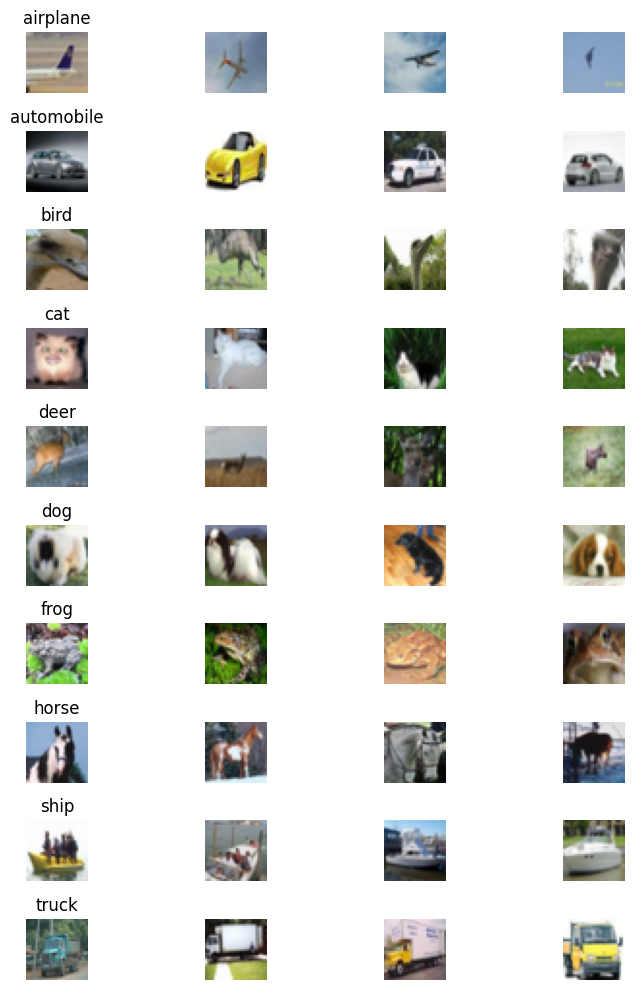

In [5]:
# 클래스 이름 목록 정의
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# 클래스당 샘플 수 및 전체 그림 설정
samples_per_class = 4
plt.figure(figsize=(samples_per_class * 2, 10))  # 가로: 클래스당 2, 세로: 10

# 클래스별 이미지 시각화
for class_id, class_name in enumerate(class_names):
    # 현재 클래스에 해당하는 인덱스 집합
    idxs = np.where(y_test == class_id)[0]
    
    # 그중에서 랜덤으로 4개 선택
    selected_idxs = np.random.choice(idxs, samples_per_class, replace=False)
    
    # 선택된 이미지들에 대한 반복
    for i, idx in enumerate(selected_idxs):
        # 서브플롯 위치 번호 계산
        plt_idx = class_id * samples_per_class + i + 1
        
        plt.subplot(10, samples_per_class, plt_idx)
        plt.imshow(X_test[idx])
        plt.axis("off")  # 축 제거
        
        # 각 클래스 첫 번째 그림에만 제목 표시
        if i == 0:
            plt.title(class_name)

plt.tight_layout()
plt.show()

### 데이터 축소
전체 데이터에서 클래스 비율(비행기 10%, 새 10% 등)을 유지하면서 표본 추출

In [6]:
# 전체 학습 데이터(50,000개)에서 10,000개만 추출
X_subset, _, y_subset, _ = train_test_split(
    X_train, y_train, train_size=10000, stratify=y_train, random_state=42
)

# 추출한 10,000개를 다시 학습(8,000개)과 테스트(2,000개)로 분리
X_train_sub, X_test_sub, y_train_sub, y_test_sub = train_test_split(
    X_subset, y_subset, test_size=0.2, stratify=y_subset, random_state=42
)

**stratify=y_train** 은 내부적으로 다음을 보장한다.

1. 각 클래스의 비율이 전체 데이터와 동일해짐
2. 클래스 불균형이 있는 경우에도 균형 유지
3. 무작위 추출이지만 “층화 표본추출(stratified sampling)” 방식 사용

In [7]:
# 데이터 정규화 및 라벨 평탄화

# 정규화 (Normalization)
X_train_sub = X_train_sub.astype("float32") / 255.0
X_test_sub  = X_test_sub.astype("float32") / 255.0

# 라벨 1차원으로 평탄화 (Flatten)
y_train_sub = y_train_sub.flatten()
y_test_sub = y_test_sub.flatten()

- *.astype("float32")*: 메모리를 아끼기 위해 
- */ 255.0*: 정규화(Min-Max Scaling)
- *.flatten()*: 2차원 배열 형태인 정답 라벨 [[1], [5], [3]]을 1차원 배열 [1, 5, 3]으로 쫙 폅니다.

### 학습 결과 시각화 함수: plot_history

In [8]:
def plot_history(history, title):
    # 한글 폰트 깨짐 방지 설정 (Windows 환경 기준)
    plt.rcParams['font.family'] = 'Malgun Gothic'
    plt.rcParams['axes.unicode_minus'] = False  # 마이너스 기호(-) 깨짐 방지

    # 그래프 틀 생성: 1행 2열 (왼쪽: 정확도, 오른쪽: 손실값)
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(title)

    # [왼쪽 그래프] 정확도(Accuracy)
    axs[0].plot(history.history['accuracy'], label='train acc')      # 학습 정확도 (실선)
    axs[0].plot(history.history['val_accuracy'], label='val acc')    # 검증 정확도 (주황색)
    axs[0].set_title("Accuracy")
    axs[0].legend()

    # [오른쪽 그래프] 손실값(Loss)
    axs[1].plot(history.history['loss'], label='train loss')         # 학습 손실값
    axs[1].plot(history.history['val_loss'], label='val loss')       # 검증 손실값
    axs[1].set_title("Loss")
    axs[1].legend()
    
    plt.show()

### 성능 평가 및 혼동 행렬 함수: evaluate_and_plot_confusion

In [9]:
def evaluate_and_plot_confusion(model, X_test, y_test, title):
    # 1. 예측 확률 계산 (예: [0.1, 0.8, 0.05 ...])
    # 2. argmax: 가장 높은 확률의 인덱스(정답 후보) 추출 (예: 1)
    y_pred = np.argmax(model.predict(X_test), axis=1)

    # 정확도 계산 및 출력
    acc = accuracy_score(y_test, y_pred)
    print(f"{title} - Test Accuracy: {acc:.4f}") # 소수점 4자리까지 출력

    # 혼동 행렬(Confusion Matrix) 생성
    cm = confusion_matrix(y_test, y_pred)
    
    # 시각화 (히트맵 그리기)
    disp = ConfusionMatrixDisplay(cm)
    disp.plot(cmap='Blues')  # 파란색 계열로 표시
    plt.title(title)
    plt.grid(False)  # 격자 무늬 제거 (깔끔하게 보기 위해)
    plt.show()

# 1. AlexNet
2012년 딥러닝 붐을 일으킨 ImageNet 대회 우승 당시의 구조를 그대로 케라스(Keras)로 구현한 AlexNet

In [10]:
# def alexnet(input_shape=(227, 227, 3), num_classes=1000):
#     model = Sequential([
#         Conv2D(96, (11, 11), strides=4, activation='relu', input_shape=input_shape),
#         MaxPooling2D(pool_size=(3, 3), strides=2),
#         Conv2D(256, (5, 5), padding="same", activation='relu'),
#         MaxPooling2D(pool_size=(3, 3), strides=2),
#         Conv2D(384, (3, 3), padding="same", activation='relu'),
#         Conv2D(384, (3, 3), padding="same", activation='relu'),
#         Conv2D(256, (3, 3), padding="same", activation='relu'),
#         MaxPooling2D(pool_size=(3, 3), strides=2),
#         Flatten(),
#         Dense(4096, activation='relu'),
#         Dropout(0.5),
#         Dense(4096, activation='relu'),
#         Dropout(0.5),
#         Dense(num_classes, activation='softmax')
#     ])
#     return model

**AlexNet (Mini 버전) 구현 및 학습**

In [11]:
def mini_alexnet(input_shape=(32, 32, 3), num_classes=10):
    model = Sequential([
        # [특징 추출부]
        # 1. 첫 번째 합성곱 층: 64개 필터, 3x3 커널
        Conv2D(64, kernel_size=3, activation='relu', input_shape=input_shape),
        MaxPooling2D(pool_size=2, strides=2), # 이미지 크기 절반 축소 (32->16)

        # 2. 두 번째 합성곱 층
        Conv2D(128, kernel_size=3, activation='relu'),
        MaxPooling2D(pool_size=2, strides=2), # 이미지 크기 절반 축소 (14->7)

        # 3. 세 번째~다섯 번째 합성곱 층 (연속적인 Conv 층으로 복잡한 특징 추출)
        Conv2D(256, kernel_size=3, activation='relu'),
        Conv2D(256, kernel_size=3, activation='relu', padding='same'), # 크기 유지 / padding = 'valid' (출력 크기가 줄어듦)
        MaxPooling2D(pool_size=2, strides=2), # 이미지 크기 절반 축소 (3->1)

        # [분류기 (Classifier)]
        Flatten(), # 1차원 벡터로 변환
        Dense(512, activation='relu'),
        Dropout(0.5), # 과적합 방지: 50% 뉴런 끄기
        Dense(256, activation='relu'),
        Dropout(0.5), # 과적합 방지
        Dense(num_classes, activation='softmax') # 최종 10개 클래스 확률 출력
    ])
    return model

alexnet_model = mini_alexnet()
alexnet_model.summary()

C:\Users\dadab\miniconda3\envs\deeplearning\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 30, 30, 64)          │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 4, 4, 256)           │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 4, 4, 256)           │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 2, 2, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,619,594 (6.18 MB)

 Trainable params: 1,619,594 (6.18 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# 컴파일
alexnet_model.compile(optimizer='adam', 
                      loss='sparse_categorical_crossentropy', 
                      metrics=['accuracy'])

# 학습 (Training)
history = alexnet_model.fit(
    X_train_sub, y_train_sub,  
    epochs=30,                 
    batch_size=128,           
    validation_split=0.1,  # 훈련 데이터를 섞은 뒤 마지막 10%를 validation으로 사용함 
    verbose=1                  
)

Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.1279 - loss: 2.2730 - val_accuracy: 0.1525 - val_loss: 2.0957
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.2049 - loss: 2.0352 - val_accuracy: 0.2463 - val_loss: 1.9724
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.2814 - loss: 1.8462 - val_accuracy: 0.4212 - val_loss: 1.6712
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.3772 - loss: 1.6603 - val_accuracy: 0.4125 - val_loss: 1.5847
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.4178 - loss: 1.5359 - val_accuracy: 0.4938 - val_loss: 1.4786
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.4695 - loss: 1.4080 - val_accuracy: 0.4963 - val_loss: 1.4015
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.4971 - loss: 1.3512 - val_accuracy: 0.5525 - val_loss: 1.2831
Epoch 8/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.5565 - loss: 1.1982 - val_accuracy: 0.5700 - v

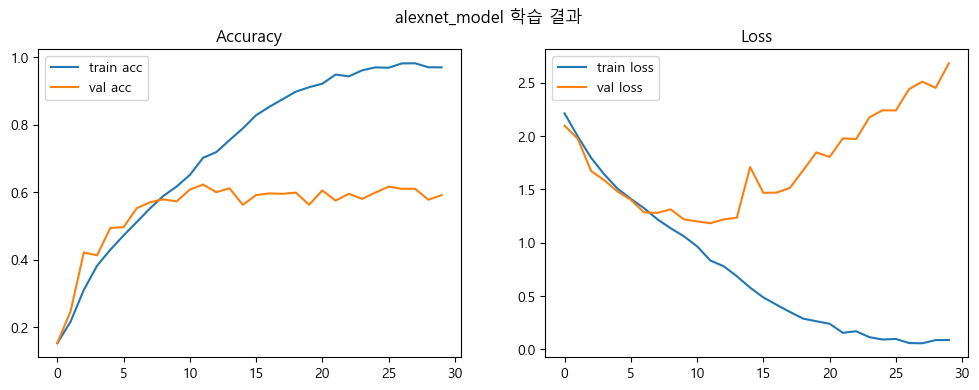

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
alexnet_model 테스트 평가 - Test Accuracy: 0.6090


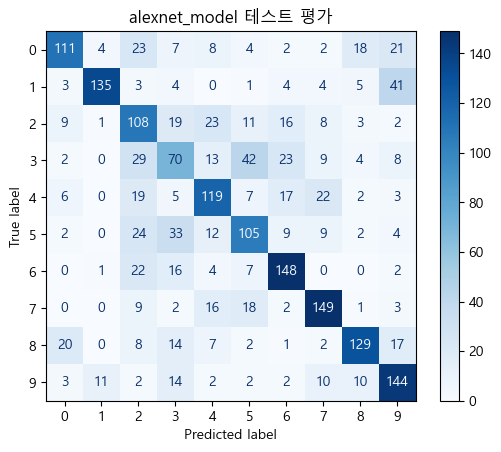

In [13]:
# 학습 곡선 그리기
plot_history(history, "alexnet_model 학습 결과")

# 테스트 데이터로 최종 평가 및 혼동 행렬 출력
evaluate_and_plot_confusion(alexnet_model, X_test_sub, y_test_sub, "alexnet_model 테스트 평가")

# 실험 자동화 함수 작성
앞서 AlexNet을 실행할 때 compile -> fit -> plot -> evaluate 과정을 일일이 코드로 쳤습니다. 앞으로 나올 ZFNet, VGGNet, ResNet 등 여러 모델에도 똑같은 과정을 반복해야 합니다. 이 과정을 자동화시기 위해서 함수 정의하겠습니다.

In [14]:
def train_and_evaluate(model_fn, model_name, X_train, y_train, X_test, y_test):
    model = model_fn(input_shape=(32, 32, 3), num_classes=10)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    history = model.fit(X_train, y_train, epochs=30, batch_size=128,
                        validation_split=0.1, verbose=1)
    plot_history(history, f"{model_name} 학습 결과")
    evaluate_and_plot_confusion(model, X_test, y_test, f"{model_name} 테스트 평가")

# 2. ZFNet
ZFNet은 2013년 **ILSVRC** 대회 우승 모델입니다. 구조를 뜯어보면 새로운 아키텍처라기보다는, 앞서 본 AlexNet의 단점을 "수리(Tuning)"한 버전에 가깝습니다.
- Large Scale Visual Recognition Challenge (ILSVRC): https://www.image-net.org/challenges/LSVRC/

In [15]:
# def zfnet(input_shape=(224, 224, 3), num_classes=1000):
#     model = Sequential([
#         Conv2D(96, (7, 7), strides=2, activation='relu', input_shape=input_shape),
#         MaxPooling2D(pool_size=(3, 3), strides=2),
#         Conv2D(256, (5, 5), padding="same", activation='relu'),
#         MaxPooling2D(pool_size=(3, 3), strides=2),
#         Conv2D(512, (3, 3), padding="same", activation='relu'),
#         Conv2D(1024, (3, 3), padding="same", activation='relu'),
#         Conv2D(512, (3, 3), padding="same", activation='relu'),
#         MaxPooling2D(pool_size=(3, 3), strides=2),
#         Flatten(),
#         Dense(4096, activation='relu'),
#         Dropout(0.5),
#         Dense(4096, activation='relu'),
#         Dropout(0.5),
#         Dense(num_classes, activation='softmax')
#     ])
#     return model

**AlexNet vs ZFNet**
ZFNet은 처음으로 CNN 내부를 시각화하여 필터가 무엇을 학습하는지 직접 확인했습니다.
그 결과, AlexNet의 11×11 필터 + stride 4는 너무 커서 많은 **Dead Filter(아무 패턴도 학습하지 않는 필터)**가 발생한다는 사실을 발견했습니다.

그래서 필터 크기를 7×7, stride를 2로 줄여
더 세밀하고 안정적인 특징을 학습하도록 개선했습니다.

- Zeiler & Fergus (2014), “Visualizing and Understanding Convolutional Networks”: https://arxiv.org/pdf/1311.2901

In [16]:
def mini_zfnet(input_shape=(32, 32, 3), num_classes=10):
    model = Sequential([
        Conv2D(64, (5, 5), strides=1, padding='same', activation='relu', input_shape=input_shape),
        MaxPooling2D(pool_size=(2, 2), strides=2),

        Conv2D(128, (3, 3), padding='same', activation='relu'),
        MaxPooling2D(pool_size=(2, 2), strides=2),

        Conv2D(256, (3, 3), padding='same', activation='relu'),
        Conv2D(256, (3, 3), padding='same', activation='relu'),
        MaxPooling2D(pool_size=(2, 2), strides=2),

        Flatten(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    return model

Epoch 1/30


C:\Users\dadab\miniconda3\envs\deeplearning\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.1074 - loss: 2.3027 - val_accuracy: 0.1088 - val_loss: 2.2995
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.1474 - loss: 2.2435 - val_accuracy: 0.2275 - val_loss: 2.0485
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.2468 - loss: 1.9889 - val_accuracy: 0.3113 - val_loss: 1.8985
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.3231 - loss: 1.8214 - val_accuracy: 0.3413 - val_loss: 1.7391
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.3351 - loss: 1.7551 - val_accuracy: 0.4175 - val_loss: 1.5913
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.4040 - loss: 1.5892 - val_accuracy: 0.4538 - val_loss: 1.5039
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.4372 - loss: 1.5332 - val_accuracy: 0.4725 - val_loss: 1.4611
Epoch 8/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.4691 - loss: 1.4003 - val_accuracy: 0.4900 - val_loss: 1.

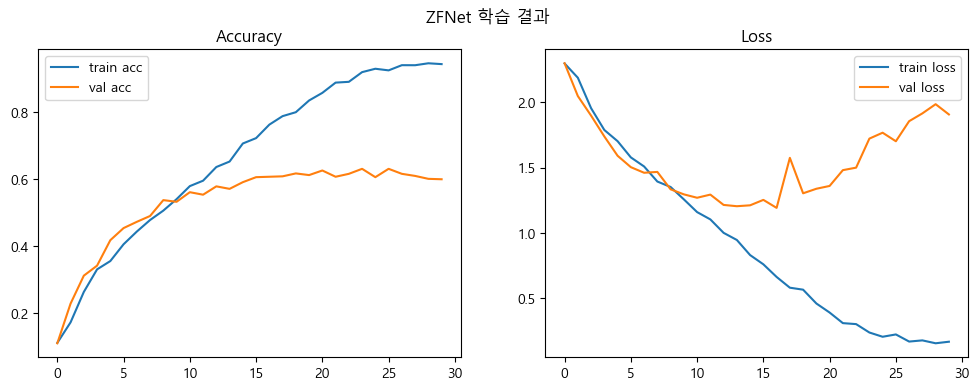

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
ZFNet 테스트 평가 - Test Accuracy: 0.5975


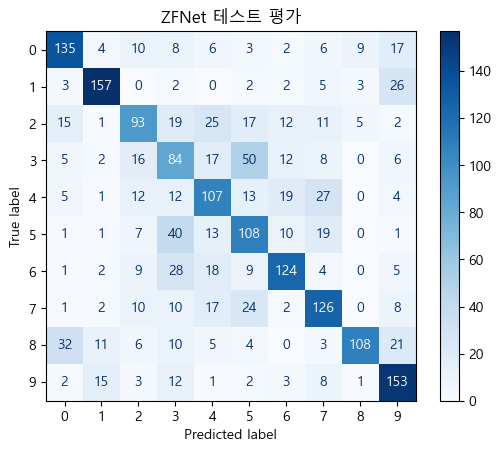

In [17]:
# 앞서 만들어둔 "자동화 함수"를 이용해 단 한 줄로 학습
train_and_evaluate(mini_zfnet, "ZFNet", X_train_sub, y_train_sub, X_test_sub, y_test_sub)

# 3. VGGNet
VGGNet(2014)은 "깊이(Depth)만으로 성능을 낼 수 있다"는 것을 보여준 모델입니다.

- Very Deep Convolutional Networks for Large-Scale Image Recognition (Simonyan & Zisserman, 2014):

   https://arxiv.org/pdf/1409.1556
                                         

In [18]:
# def vgg16(input_shape=(224, 224, 3), num_classes=1000):
#     model = Sequential()
#     # Conv Block 1
#     model.add(Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=input_shape))
#     model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
#     model.add(MaxPooling2D((2, 2)))
#     # Conv Block 2
#     model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
#     model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
#     model.add(MaxPooling2D((2, 2)))
#     # Conv Block 3
#     model.add(Conv2D(256, (3, 3), activation='relu', padding='same'))
#     model.add(Conv2D(256, (3, 3), activation='relu', padding='same'))
#     model.add(Conv2D(256, (3, 3), activation='relu', padding='same'))
#     model.add(MaxPooling2D((2, 2)))
#     # Conv Block 4
#     model.add(Conv2D(512, (3, 3), activation='relu', padding='same'))
#     model.add(Conv2D(512, (3, 3), activation='relu', padding='same'))
#     model.add(Conv2D(512, (3, 3), activation='relu', padding='same'))
#     model.add(MaxPooling2D((2, 2)))
#     # Conv Block 5
#     model.add(Conv2D(512, (3, 3), activation='relu', padding='same'))
#     model.add(Conv2D(512, (3, 3), activation='relu', padding='same'))
#     model.add(Conv2D(512, (3, 3), activation='relu', padding='same'))
#     model.add(MaxPooling2D((2, 2)))
#     # FC layers
#     model.add(Flatten())
#     model.add(Dense(4096, activation='relu'))
#     model.add(Dropout(0.5))
#     model.add(Dense(4096, activation='relu'))
#     model.add(Dropout(0.5))
#     model.add(Dense(num_classes, activation='softmax'))
#     return model

In [19]:
def mini_vgg16(input_shape=(32, 32, 3), num_classes=10):
    model = Sequential()
    # Block 1
    model.add(Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape))
    model.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
    model.add(MaxPooling2D((2, 2)))

    # Block 2
    model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(MaxPooling2D((2, 2)))

    # Block 3
    model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(MaxPooling2D((2, 2)))

    # FC layers
    model.add(Flatten())
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(num_classes, activation='softmax'))
    return model

In [20]:
vgg16_model = mini_vgg16(input_shape=(32, 32, 3), num_classes=10)
vgg16_model.summary()

C:\Users\dadab\miniconda3\envs\deeplearning\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)                    │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 32, 32, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 16, 16, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_12 (Conv2D)                   │ (None, 8, 8, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_13 (Conv2D)                   │ (None, 8, 8, 128)           │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 4, 4, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 814,122 (3.11 MB)

 Trainable params: 814,122 (3.11 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.1451 - loss: 2.2307 - val_accuracy: 0.2525 - val_loss: 1.9779
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.2751 - loss: 1.9425 - val_accuracy: 0.2775 - val_loss: 1.9618
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.3077 - loss: 1.8364 - val_accuracy: 0.3438 - val_loss: 1.7199
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.3638 - loss: 1.7051 - val_accuracy: 0.4212 - val_loss: 1.5672
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4171 - loss: 1.5663 - val_accuracy: 0.4250 - val_loss: 1.5591
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4647 - loss: 1.4653 - val_accuracy: 0.4888 - val_loss: 1.4338
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4986 - loss: 1.3786 - val_accuracy: 0.5537 - val_loss: 1.2882
Epoch 8/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.5327 - loss: 1.2773 - val_accuracy: 0.5562 - v

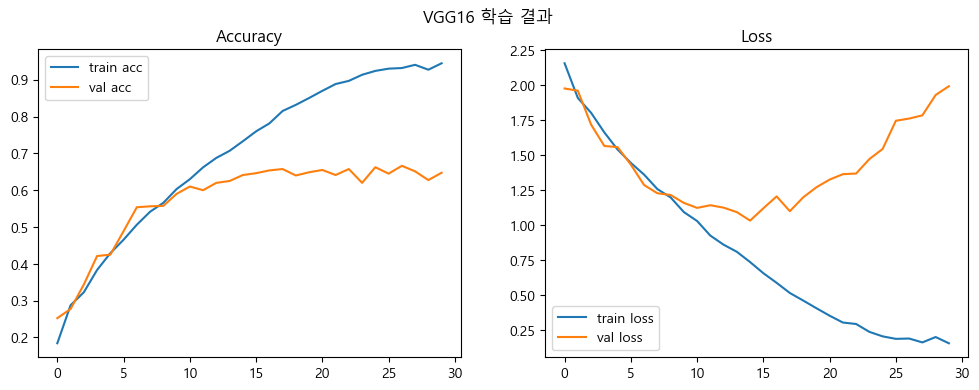

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step   
VGG16 테스트 평가 - Test Accuracy: 0.6590


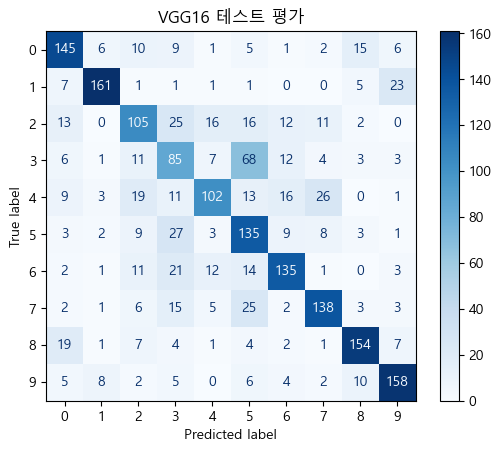

In [21]:
train_and_evaluate(mini_vgg16, "VGG16",X_train_sub,y_train_sub,X_test_sub, y_test_sub)

# 4. GoogLeNet
혁신 포인트: CNN이 단일 필터 크기에 의존하던 방식에서 벗어나 다중 해상도 특징 추출 + 연산 최적화라는 새로운 패러다임 제시 (ILSVRC 2014 우승 모델 (classification 1위))

- Going Deeper with Convolutions (GoogLeNet / Inception v1): https://arxiv.org/pdf/1409.4842

**인셉션 모듈 핵심 요약**

CNN에서 “3×3을 쓸까, 5×5를 쓸까, 풀링을 할까?”라는 선택 문제를
GoogLeNet은 모두 병렬로 수행하는 방식으로 해결했습니다. 즉,

- 1×1 Conv
- 3×3 Conv
- 5×5 Conv
- 3×3 Pooling

을 동시에 적용한 뒤 출력들을 합쳐(Concatenate) 다음 층으로 전달합니다. 이 구조 덕분에 여러 크기의 특징을 한 번에 추출할 수 있습니다.

In [22]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, concatenate, BatchNormalization

In [23]:
# def inception_module(x, f1, f3_in, f3_out, f5_in, f5_out, proj):
#     path1 = Conv2D(f1, (1, 1), padding='same', activation='relu')(x)

#     path2 = Conv2D(f3_in, (1, 1), padding='same', activation='relu')(x)
#     path2 = Conv2D(f3_out, (3, 3), padding='same', activation='relu')(path2)

#     path3 = Conv2D(f5_in, (1, 1), padding='same', activation='relu')(x)
#     path3 = Conv2D(f5_out, (5, 5), padding='same', activation='relu')(path3)

#     path4 = MaxPooling2D((3, 3), strides=1, padding='same')(x)
#     path4 = Conv2D(proj, (1, 1), padding='same', activation='relu')(path4)

#     return concatenate([path1, path2, path3, path4], axis=-1)

# def googlenet(input_shape=(224, 224, 3), num_classes=1000):
#     input_layer = Input(shape=input_shape)

#     x = Conv2D(64, (7, 7), strides=(2, 2), padding='same', activation='relu')(input_layer)
#     x = MaxPooling2D((3, 3), strides=2, padding='same')(x)
#     x = BatchNormalization()(x)

#     x = Conv2D(64, (1, 1), activation='relu')(x)
#     x = Conv2D(192, (3, 3), padding='same', activation='relu')(x)
#     x = BatchNormalization()(x)
#     x = MaxPooling2D((3, 3), strides=2, padding='same')(x)

#     # Inception blocks
#     x = inception_module(x, 64, 96, 128, 16, 32, 32)
#     x = inception_module(x, 128, 128, 192, 32, 96, 64)
#     x = MaxPooling2D((3, 3), strides=2, padding='same')(x)

#     x = inception_module(x, 192, 96, 208, 16, 48, 64)
#     x = inception_module(x, 160, 112, 224, 24, 64, 64)
#     x = inception_module(x, 128, 128, 256, 24, 64, 64)
#     x = inception_module(x, 112, 144, 288, 32, 64, 64)
#     x = inception_module(x, 256, 160, 320, 32, 128, 128)
#     x = MaxPooling2D((3, 3), strides=2, padding='same')(x)

#     x = inception_module(x, 256, 160, 320, 32, 128, 128)
#     x = inception_module(x, 384, 192, 384, 48, 128, 128)

#     x = GlobalAveragePooling2D()(x)
#     x = Dropout(0.4)(x)
#     output = Dense(num_classes, activation='softmax')(x)

#     model = Model(inputs=input_layer, outputs=output, name="GoogLeNet")
#     return model

**인셉션**은 하나의 층 안에서 여러 종류의 필터(1×1, 3×3, 5×5)와 Pooling을 동시에 적용하고,
그 결과들을 채널 방향으로 합치는(concatenate) 구조입니다.

In [24]:
def mini_googlenet(input_shape=(32, 32, 3), num_classes=10):
    input_layer = Input(shape=input_shape)

    # [초반부] 일반적인 CNN 구조 (특징 추출 시작)
    x = Conv2D(32, (3, 3), padding='same', activation='relu')(input_layer)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2), strides=2)(x)

    # ---------------------------------------------------------
    # [핵심] 인셉션 모듈 정의 (내부 함수) - 아래 4개의 경로를 병렬로 수행
    # ---------------------------------------------------------
    def inception_module(x, f1, f3_in, f3_out, f5_in, f5_out, proj):
        
        # x: 인셉션 모듈로 들어오는 입력 텐서
        # f1: 1×1 Conv 경로의 필터 개수
        # f3_in: 3×3 Conv 전에 쓰는 1×1 병목 필터 개수
        # f3_out: 실제 3×3 Conv의 필터 개수
        # f5_in: 5×5 Conv 전에 쓰는 1×1 병목 필터 개수
        # f5_out: 실제 5×5 Conv의 필터 개수
        # proj: Pooling 후 1×1 Conv에서 사용할 필터 개수
        
        # 경로 1: 1x1 합성곱 (연산량 감소 및 특징 압축)
        path1 = Conv2D(f1, (1, 1), padding='same', activation='relu')(x)

        # 경로 2: 1x1(병목) -> 3x3 합성곱
        path2 = Conv2D(f3_in, (1, 1), padding='same', activation='relu')(x)
        path2 = Conv2D(f3_out, (3, 3), padding='same', activation='relu')(path2)

        # 경로 3: 1x1(병목) -> 5x5 합성곱
        path3 = Conv2D(f5_in, (1, 1), padding='same', activation='relu')(x)
        path3 = Conv2D(f5_out, (5, 5), padding='same', activation='relu')(path3)

        # 경로 4: MaxPool -> 1x1 합성곱
        path4 = MaxPooling2D((3, 3), strides=1, padding='same')(x)
        path4 = Conv2D(proj, (1, 1), padding='same', activation='relu')(path4)

        # 4개의 경로를 하나로 합침 (채널 방향으로 붙임)
        return concatenate([path1, path2, path3, path4], axis=-1)

    # 인셉션 모듈 적용 (Block 1)
    x = inception_module(x, 32, 32, 64, 8, 16, 16)
    x = MaxPooling2D((2, 2), strides=2)(x)

    # 인셉션 모듈 적용 (Block 2)
    x = inception_module(x, 64, 64, 96, 16, 32, 32)
    
    # [Global Average Pooling]
    x = GlobalAveragePooling2D()(x) # GAP는 각 채널의 평균값만 뽑아서, 특징맵을 1차원 벡터로 압축하는 역할을 한다.
    
    output = Dense(num_classes, activation='softmax')(x)
    model = Model(inputs=input_layer, outputs=output, name="MiniGoogLeNet")
    return model

Sequential은 단순 직렬 구조라 자동 연결되고, Functional API는 복잡한 구조 표현을 위해 (x)로 직접 연결을 지정해야 한다.

(x) → 이전 층의 출력 x를 이 Dense 층의 입력값으로 전달

- **Sequential**: “일자형 모델” 레이어를 위→아래로 순서대로 쌓기만 하면 자동 연결됨
- **Model** – Functional API: “그래프 모델” 입력과 출력을 사용자가 직접 연결해서 모델을 정의

In [25]:
mini_googlenet_model = mini_googlenet(input_shape=(32, 32, 3), num_classes=10)
mini_googlenet_model.summary()

Model: "MiniGoogLeNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)    │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_20 (Conv2D)            │ (None, 32, 32, 32)        │             896 │ input_layer_4[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 32, 32, 32)        │             128 │ conv2d_20[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_12              │ (None, 16, 16, 32)        │               0 │ batch_normalization[0][0]  │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_22 (Conv2D)            │ (None, 16, 16, 32)        │           1,056 │ max_pooling2d_12[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_24 (Conv2D)            │ (None, 16, 16, 8)         │             264 │ max_pooling2d_12[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_13              │ (None, 16, 16, 32)        │               0 │ max_pooling2d_12[0][0]     │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_21 (Conv2D)            │ (None, 16, 16, 32)        │           1,056 │ max_pooling2d_12[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_23 (Conv2D)            │ (None, 16, 16, 64)        │          18,496 │ conv2d_22[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_25 (Conv2D)            │ (None, 16, 16, 16)        │           3,216 │ conv2d_24[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_26 (Conv2D)            │ (None, 16, 16, 16)        │             528 │ max_pooling2d_13[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 16, 16, 128)       │               0 │ conv2d_21[0][0],           │
│                               │                           │                 │ conv2d_23[0][0],           │
│                               │                           │                 │ conv2d_25[0][0],           │
│                               │                           │                 │ conv2d_26[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_14              │ (None, 8, 8, 128)         │               0 │ concatenate[0][0]          │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_28 (Conv2D)            │ (None, 8, 8, 64)          │           8,25

 Total params: 118,818 (464.13 KB)

 Trainable params: 118,754 (463.88 KB)

 Non-trainable params: 64 (256.00 B)

Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.1861 - loss: 2.1864 - val_accuracy: 0.1538 - val_loss: 2.3054
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.3638 - loss: 1.7328 - val_accuracy: 0.2050 - val_loss: 2.2503
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.4092 - loss: 1.6142 - val_accuracy: 0.1725 - val_loss: 2.3122
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.4274 - loss: 1.5520 - val_accuracy: 0.1975 - val_loss: 2.0861
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.4853 - loss: 1.4589 - val_accuracy: 0.2912 - val_loss: 1.9571
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.5005 - loss: 1.3817 - val_accuracy: 0.2988 - val_loss: 1.8934
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.5141 - loss: 1.3175 - val_accuracy: 0.3750 - val_loss: 1.7659
Epoch 8/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.5251 - loss: 1.2806 - val_accuracy: 0.4625 - v

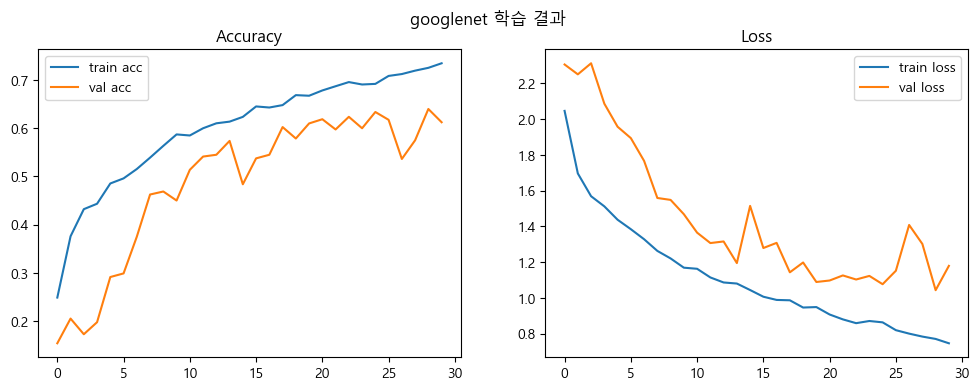

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
googlenet 테스트 평가 - Test Accuracy: 0.6190


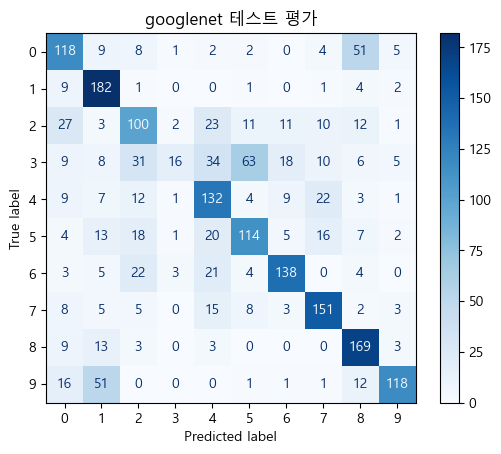

In [26]:
train_and_evaluate(mini_googlenet, "googlenet",X_train_sub,y_train_sub,X_test_sub, y_test_sub)

![my image](Code_Generated_Image.png)

VGG16 — Serial & Deep (직렬·깊이 중심)

- 구조: Conv → Conv → Pool 을 단계별로 “위에서 아래로” 직렬로 쌓는 일자형 구조
- 특징: 단순하고 규칙적인 블록 반복 (3×3 Conv만 사용)
- 단점: 마지막 Flatten + 큰 Dense 층 때문에 파라미터 수가 매우 많아짐 (무거움)

GoogLeNet(Inception v1) — Parallel & Wide (병렬·너비 중심)

- 구조 핵심: Inception 모듈 → 여러 필터(1×1, 3×3, 5×5)와 Pooling을 병렬로 수행하고 결과(feature maps)를 채널 방향으로 합침(concatenate)
- 특징: 여러 크기의 특징을 동시에 추출한 뒤 Concatenate로 합쳐서 전달
- 장점: 다양한 특징을 한 번에 잡는 멀티스케일 학습

마지막에 Global Average Pooling(GAP) 사용 → Dense층 제거 → VGG보다 훨씬 적은 파라미터(가벼움)

# 5. ResNet (Residual Network)
ResNet(2015)은 딥러닝 큰 변곡점 - 이 모델 덕분에 인공지능은 20개 층의 한계를 넘어 100개, 1000개 이상의 층을 쌓을 수 있게 되었습니다.
- Deep Residual Learning for Image Recognition: https://arxiv.org/pdf/1512.03385

**깊은 네트워크의 근본 문제**: 신경망을 너무 깊게 만들면 “새로운 기능을 배우는 것”보다 기존 정보를 보존하는 것 자체가 어려워집니다. 예를 들면 입력 이미지의 중요한 패턴은 앞쪽에서 잡혔는데, 50층·100층을 지나면서 그 정보가 계속 희미해집니다.

**ResNet** 은 입력을 그대로 다음 층으로 보내는 스킵 연결을 사용해, 네트워크가 전체 출력을 직접 학습하는 대신 ‘얼마나 수정할지(잔차)’만 학습하도록 만든 구조이다.

In [27]:
from tensorflow.keras.layers import Input, Conv2D, BatchNormalization, Activation, Add, GlobalAveragePooling2D, Dense, MaxPooling2D
from tensorflow.keras.models import Model

In [28]:
def residual_block(x, filters, downsample=False):
    
    # x 이전 레이어의 출력(feature map)
    # filters 이 Residual Block에서 사용할 합성곱(Conv2D)의 필터 개수(출력 채널 수)
    # downsample (기본값=False) 블록에서 feature map의 크기를 줄일지 여부
    
    stride = 2 if downsample else 1
    # downsample=True → stride=2 (크기 축소)
    # downsample=False → stride=1 (크기 유지)
    
    shortcut = x # shortcut = Skip Connection(잔차 연결)에 필요한 원본 입력 저장
 
    x = Conv2D(filters, (3, 3), strides=stride, padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)

    x = Conv2D(filters, (3, 3), strides=1, padding='same')(x)
    x = BatchNormalization()(x)

    if downsample or shortcut.shape[-1] != filters:
        shortcut = Conv2D(filters, (1, 1), strides=stride, padding='same')(shortcut)
        shortcut = BatchNormalization()(shortcut)

    x = Add()([x, shortcut])
    return Activation('relu')(x)


In [29]:
# CIFAR-10 용 경량 ResNet18
def mini_resnet18(input_shape=(32, 32, 3), num_classes=10):
    inputs = Input(shape=input_shape)
    
    x = Conv2D(64, (3, 3), strides=1, padding='same')(inputs)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)

    # 각 블록에 2개 residual block
    for filters, blocks in zip([64, 128, 256], [2, 2, 2]):
        for i in range(blocks):
            x = residual_block(x, filters, downsample=(i == 0 and filters != 64)) # Stage의 첫 블록(i=0) 이고, 필터 수가 64가 아니라면 True (즉 Stage 2~3)

    x = GlobalAveragePooling2D()(x)
    outputs = Dense(num_classes, activation='softmax')(x)
    model = Model(inputs, outputs, name="MiniResNet18")
    return model

In [30]:
mini_resnet18_model = mini_resnet18(input_shape=(32, 32, 3), num_classes=10)
mini_resnet18_model.summary()

Model: "MiniResNet18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)    │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_46 (Conv2D)            │ (None, 32, 32, 64)        │           1,792 │ input_layer_6[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_2         │ (None, 32, 32, 64)        │             256 │ conv2d_46[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 32, 32, 64)        │               0 │ batch_normalization_2[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_47 (Conv2D)            │ (None, 32, 32, 64)        │          36,928 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_3         │ (None, 32, 32, 64)        │             256 │ conv2d_47[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_1 (Activation)     │ (None, 32, 32, 64)        │               0 │ batch_normalization_3[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_48 (Conv2D)            │ (None, 32, 32, 64)        │          36,928 │ activation_1[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_4         │ (None, 32, 32, 64)        │             256 │ conv2d_48[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 32, 32, 64)        │               0 │ batch_normalization_4[0][… │
│                               │                           │                 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_2 (Activation)     │ (None, 32, 32, 64)        │               0 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_49 (Conv2D)            │ (None, 32, 32, 64)        │          36,928 │ activation_2[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_5         │ (None, 32, 32, 64)        │             256 │ conv2d_49[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_3 (Activation)     │ (None, 32, 32, 64)        │               0 │ batch_normalization_5[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_50 (Conv2D)            │ (None, 32, 32, 64)        │          36,92

 Total params: 2,784,394 (10.62 MB)

 Trainable params: 2,779,914 (10.60 MB)

 Non-trainable params: 4,480 (17.50 KB)

Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 390ms/step - accuracy: 0.3037 - loss: 2.0745 - val_accuracy: 0.0875 - val_loss: 3.0675
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 22s 380ms/step - accuracy: 0.4968 - loss: 1.3786 - val_accuracy: 0.1800 - val_loss: 3.3726
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 22s 380ms/step - accuracy: 0.5649 - loss: 1.1765 - val_accuracy: 0.1013 - val_loss: 3.9120
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 22s 388ms/step - accuracy: 0.6382 - loss: 1.0270 - val_accuracy: 0.1637 - val_loss: 3.9249
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 22s 384ms/step - accuracy: 0.6824 - loss: 0.8922 - val_accuracy: 0.2512 - val_loss: 2.5582
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 22s 382ms/step - accuracy: 0.7352 - loss: 0.7632 - val_accuracy: 0.2738 - val_loss: 2.8580
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 22s 383ms/step - accuracy: 0.7775 - loss: 0.6404 - val_accuracy: 0.3562 - val_loss: 2.3129
Epoch 8/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 22s 385ms/step - accuracy: 0.8297 - loss: 0.4953 - val_accu

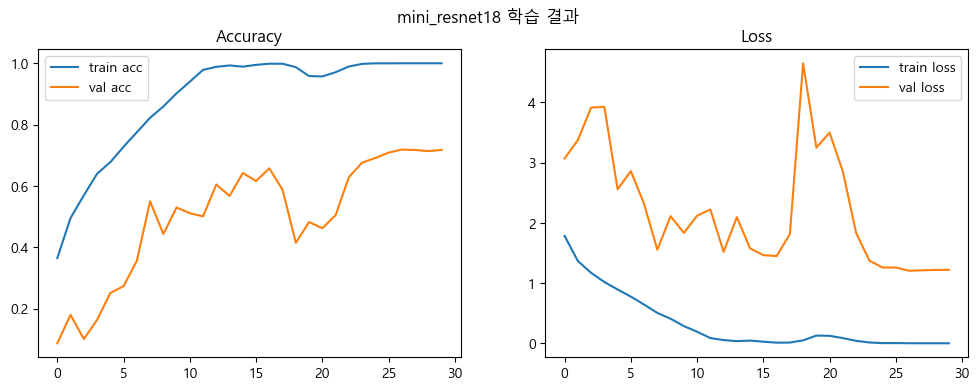

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step
mini_resnet18 테스트 평가 - Test Accuracy: 0.7330


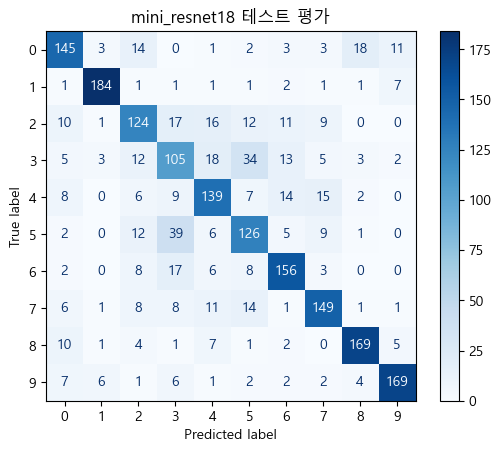

In [31]:
train_and_evaluate(mini_resnet18, "mini_resnet18",X_train_sub,y_train_sub,X_test_sub, y_test_sub)

# 6. 전이학습 VGG 16
전이 학습은 모델을 백지 상태에서 처음부터 가르치는 대신, 이미 ImageNet 같은 초대규모 데이터로 학습을 끝낸 "똑똑한 모델"을 가져와서, 우리 문제에 맞게 조금만 재교육(fine-tuning)하는 방법입니다.
- Pretrained Model (weights='imagenet'): VGG16은 ImageNet(1,400만 장, 1,000개 클래스)으로 이미 학습되어 있어, 기본적인 시각 패턴(선·면·엣지·눈·코·입·자동차 바퀴 등)을 이미 잘 인식합니다.
- 특징 추출기(feature extractor): VGG16의 Conv 블록들 → 동결(Freeze) → 기존 학습된 시각 지식을 그대로 사용
- 분류기(Classifier): 마지막 Dense 층들 → 새로 구성해서 CIFAR-10에 맞게 학습

In [32]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [33]:
def build_transfer_vgg16(input_shape=(32, 32, 3), num_classes=10):
    # 1. Pretrained VGG16 불러오기
    # include_top=False: 마지막 분류기(1000개 클래스용)는 떼고 가져옴
    # weights='imagenet': 학습된 지능(가중치)을 그대로 가져옴
    base_model = VGG16(weights='imagenet', include_top=False, input_shape=input_shape)
    
    # [핵심] 전체 Conv block 얼리기 (학습되지 않도록 설정)
    base_model.trainable = False 

    # 2. 나만의 출력층 추가 (Fine-tuning head)
    x = Flatten()(base_model.output)     # VGG의 출력을 펼침
    x = Dense(256, activation='relu')(x) # 내 데이터에 맞는 새로운 해석 층
    x = Dropout(0.5)(x)                  # 과적합 방지
    output = Dense(num_classes, activation='softmax')(x) # 최종 10개 분류

    model = Model(inputs=base_model.input, outputs=output)
    return model

**weights**: 모델이 어떤 가중치로 시작할지 결정
   - imagenet ImageNet으로 미리 학습된 가중치 사용
   - None 가중치를 랜덤 초기화
   - 파일경로 사용자가 저장한 .h5 가중치 파일을 불러올 때 사용

**include_top** 원래 VGG16의 마지막 분류기(FC 층)를 포함할지 결정
- False 마지막 Dense 분류기 제거, 앞부분 Conv 블록만 사용
- True (기본) 원래 1000 클래스 분류기 포함

In [34]:
model = build_transfer_vgg16(input_shape=(32, 32, 3), num_classes=10)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(
    X_train_sub, y_train_sub,
    validation_split=0.1,
    epochs=30,
    batch_size=64,
    callbacks=[EarlyStopping(patience=3, restore_best_weights=True)],
    verbose=2
)

Epoch 1/30
113/113 - 5s - 45ms/step - accuracy: 0.1493 - loss: 2.3228 - val_accuracy: 0.2900 - val_loss: 2.0850
Epoch 2/30
113/113 - 4s - 38ms/step - accuracy: 0.2435 - loss: 2.0873 - val_accuracy: 0.3862 - val_loss: 1.9192
Epoch 3/30
113/113 - 4s - 36ms/step - accuracy: 0.3128 - loss: 1.9303 - val_accuracy: 0.4175 - val_loss: 1.8142
Epoch 4/30
113/113 - 4s - 37ms/step - accuracy: 0.3531 - loss: 1.8372 - val_accuracy: 0.4462 - val_loss: 1.7335
Epoch 5/30
113/113 - 4s - 36ms/step - accuracy: 0.3826 - loss: 1.7667 - val_accuracy: 0.4525 - val_loss: 1.6758
Epoch 6/30
113/113 - 4s - 36ms/step - accuracy: 0.4093 - loss: 1.7078 - val_accuracy: 0.4600 - val_loss: 1.6258
Epoch 7/30
113/113 - 4s - 35ms/step - accuracy: 0.4219 - loss: 1.6564 - val_accuracy: 0.4825 - val_loss: 1.5874
Epoch 8/30
113/113 - 4s - 36ms/step - accuracy: 0.4426 - loss: 1.6243 - val_accuracy: 0.4812 - val_loss: 1.5608
Epoch 9/30
113/113 - 4s - 35ms/step - accuracy: 0.4510 - loss: 1.5869 - val_accuracy: 0.4837 - val_loss:

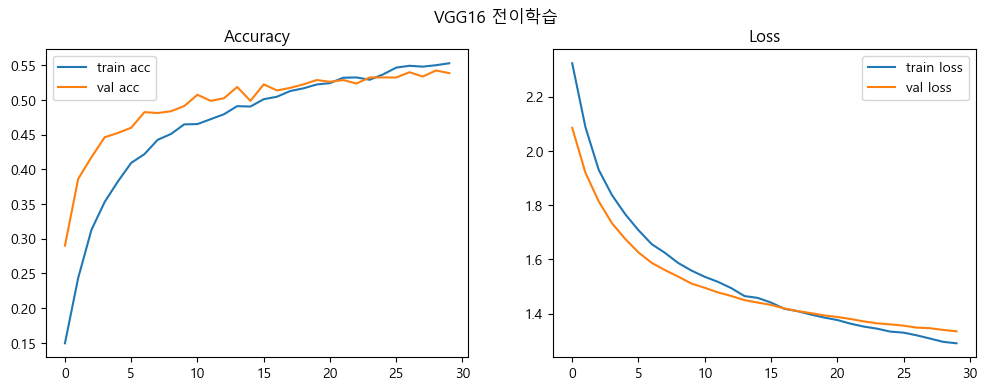

In [35]:
plot_history(history, "VGG16 전이학습")

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step
VGG16 전이학습 - Test Accuracy: 0.5500


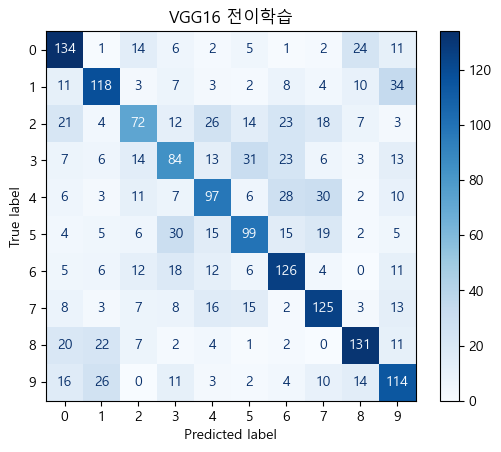

In [36]:
evaluate_and_plot_confusion(model, X_test_sub, y_test_sub, "VGG16 전이학습")

# R-CNN, Yolo, Mask R-CNN, 얼굴인식, 스타일 변환